# Saudi Road Safety Analytics | 2023–2024

**Descriptive analysis of Saudi road transport statistics**  
**Source:** General Authority for Statistics (GASTAT), *Road Transport Statistics 2024* (Arabic Excel workbook).  
**Scope:** National comparisons for 2023–2024 and regional serious road accidents in 2024, including within- and outside-city counts.  
**Tools:** Python, pandas, NumPy, matplotlib, seaborn. No machine learning.

**Data source and verification:** The notebook uses a fixed data snapshot reconstructed from the earlier project notebook, so its main analysis can run without an internet connection. This snapshot was subsequently compared with the official GASTAT Arabic workbook: all 39 regional values (13 regions × within-city, outside-city, and total counts) matched, as did the checked national indicators. Section 8 provides an independent audit that runs when the official Excel workbook is available alongside this notebook. The full project package includes the workbook and a regional audit CSV.


## 1. Questions and analytical design

1. How did reported serious accidents, fatalities and injuries change from 2023 to 2024?
2. Which regions contributed most to the 2024 serious-accident count?
3. How do the within-city and outside-city distributions differ by region?
4. What can and cannot be concluded from these aggregate counts?

**Unit of analysis:** national year or administrative region. **Important:** Fatalities and injuries are persons, while serious accidents are events. Rates per 100 accidents below are *ratios of reported counts*, not the probability that an accident caused a death or injury. No causal or individual-level conclusions are warranted.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
OUTPUT_DIR = Path("road_safety_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
print("Environment ready | pandas", pd.__version__)

Environment ready | pandas 2.2.3


## 2. Data used in this analysis

The national figures and 13-region table are embedded in the notebook for repeatable analysis. They were originally reconstructed from `Saudi_Road_Safety_Analytics-2(1).ipynb` and subsequently compared with the official GASTAT Arabic Excel workbook, *Road Transport Statistics 2024*.

**Verification references:** Sheet `5-5` (2024 regional serious accidents: within cities, outside cities, total), sheet `5-3` (annual serious accident totals), and sheet `5-1` (2024 national fatalities and injuries). The regional comparison found **39/39 exact matches**. The independent check can be rerun in Section 8 with `Road Transport Statistics 2024_AR (1).xlsx` in the notebook's working directory.


In [2]:
annual = pd.DataFrame({
    "Year": [2023, 2024],
    "Serious_Accidents": [16534, 17231],
    "Fatalities": [4423, 4282],
    "Injuries": [24002, 24077],
})

regional = pd.DataFrame([
    ("Riyadh", 3150, 1046, 4196),
    ("Makkah", 3620, 2205, 5825),
    ("Madinah", 1126, 651, 1777),
    ("Qassim", 395, 268, 663),
    ("Eastern Region", 998, 724, 1722),
    ("Aseer", 104, 688, 792),
    ("Tabuk", 207, 265, 472),
    ("Hail", 115, 88, 203),
    ("Northern Borders", 131, 47, 178),
    ("Jazan", 222, 505, 727),
    ("Najran", 87, 108, 195),
    ("Al-Baha", 146, 201, 347),
    ("Al-Jouf", 91, 43, 134),
], columns=["Region", "Within_Cities", "Outside_Cities", "Total_Accidents"])

display(annual)
display(regional)

,Year,Serious_Accidents,Fatalities,Injuries
0,2023,16534,4423,24002
1,2024,17231,4282,24077


,Region,Within_Cities,Outside_Cities,Total_Accidents
0,Riyadh,3150,1046,4196
1,Makkah,3620,2205,5825
2,Madinah,1126,651,1777
3,Qassim,395,268,663
4,Eastern Region,998,724,1722
5,Aseer,104,688,792
6,Tabuk,207,265,472
7,Hail,115,88,203
8,Northern Borders,131,47,178
9,Jazan,222,505,727


## 3. Data quality and consistency checks

The checks below verify the embedded dataset's structure, missing values, uniqueness, arithmetic consistency, and national totals. These checks are distinct from the **official-workbook comparison** in Section 8; both forms of validation are included for transparency.


In [3]:
expected_regions = {
    "Riyadh", "Makkah", "Madinah", "Qassim", "Eastern Region",
    "Aseer", "Tabuk", "Hail", "Northern Borders", "Jazan",
    "Najran", "Al-Baha", "Al-Jouf"
}
assert set(regional.Region) == expected_regions
assert len(regional) == 13 and regional.Region.is_unique
assert annual.Year.tolist() == [2023, 2024]
assert not annual.isna().any().any() and not regional.isna().any().any()
assert (annual.iloc[:, 1:] >= 0).all().all()
assert (regional.iloc[:, 1:] >= 0).all().all()
assert (regional.Within_Cities + regional.Outside_Cities == regional.Total_Accidents).all()
assert regional.Total_Accidents.sum() == int(annual.loc[annual.Year.eq(2024), "Serious_Accidents"].iloc[0])
assert regional.Within_Cities.sum() == 10392
assert regional.Outside_Cities.sum() == 6839
assert annual.loc[annual.Year.eq(2024), "Fatalities"].iloc[0] == 4282
assert annual.loc[annual.Year.eq(2024), "Injuries"].iloc[0] == 24077
print("PASS: internal data consistency, regional coverage, and snapshot reference totals")
print("2024 accidents:", regional.Total_Accidents.sum())

PASS: internal data consistency, regional coverage, and snapshot reference totals
2024 accidents: 17231


## 4. National trend and severity ratios

A two-year comparison can show changes in reported counts but cannot establish a trend beyond this interval. Percent change uses 2023 as the denominator.

In [4]:
metrics = ["Serious_Accidents", "Fatalities", "Injuries"]
comparison = annual.set_index("Year")[metrics].T.rename(columns={2023:"2023", 2024:"2024"})
comparison["Absolute_Change"] = comparison["2024"] - comparison["2023"]
comparison["Pct_Change"] = 100 * comparison["Absolute_Change"] / comparison["2023"]
display(comparison.style.format({"2023":"{:,.0f}","2024":"{:,.0f}","Absolute_Change":"{:+,.0f}","Pct_Change":"{:+.2f}%"}))

annual["Fatalities_per_100_Accidents"] = 100 * annual.Fatalities / annual.Serious_Accidents
annual["Injuries_per_100_Accidents"] = 100 * annual.Injuries / annual.Serious_Accidents
display(annual.round(2))

Year,2023,2024,Absolute_Change,Pct_Change
Serious_Accidents,"16,534","17,231",+697,+4.22%
Fatalities,"4,423","4,282",-141,-3.19%
Injuries,"24,002","24,077",+75,+0.31%


,Year,Serious_Accidents,Fatalities,Injuries,Fatalities_per_100_Accidents,Injuries_per_100_Accidents
0,2023,16534,4423,24002,26.75,145.17
1,2024,17231,4282,24077,24.85,139.73


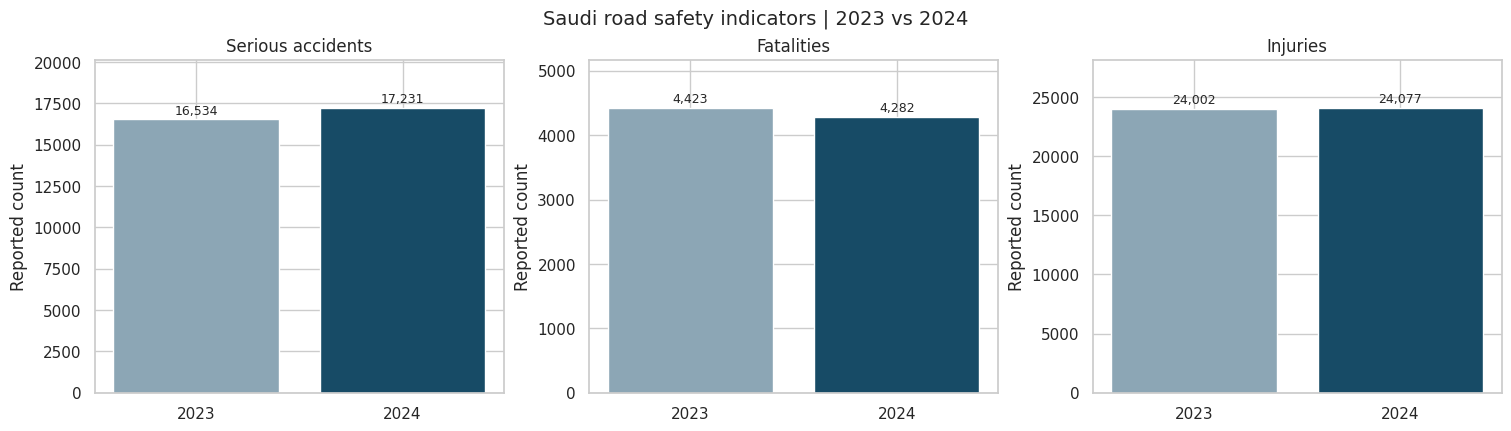

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
for ax, metric, title in zip(axes, metrics, ["Serious accidents", "Fatalities", "Injuries"]):
    ax.bar(annual.Year.astype(str), annual[metric], color=["#8CA6B5", "#174B66"])
    for i, v in enumerate(annual[metric]):
        ax.annotate(f"{v:,}", (i, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
    ax.set_title(title)
    ax.set_ylabel("Reported count")
    ax.set_ylim(0, annual[metric].max() * 1.17)
fig.suptitle("Saudi road safety indicators | 2023 vs 2024", fontsize=14)
fig.savefig(OUTPUT_DIR / "01_national_indicators.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Regional distribution in 2024

These are **absolute accident counts**, not region-specific risk rates. Regions differ in population, road network, and traffic exposure; ranking by counts alone does not identify the most dangerous roads or regions.

,Region,Within_Cities,Outside_Cities,Total_Accidents,National_Share_Pct,Within_Cities_Pct,Outside_Cities_Pct
0,Makkah,3620,2205,5825,33.81,62.15,37.85
1,Riyadh,3150,1046,4196,24.35,75.07,24.93
2,Madinah,1126,651,1777,10.31,63.37,36.63
3,Eastern Region,998,724,1722,9.99,57.96,42.04
4,Aseer,104,688,792,4.60,13.13,86.87
5,Jazan,222,505,727,4.22,30.54,69.46
6,Qassim,395,268,663,3.85,59.58,40.42
7,Tabuk,207,265,472,2.74,43.86,56.14
8,Al-Baha,146,201,347,2.01,42.07,57.93
9,Hail,115,88,203,1.18,56.65,43.35


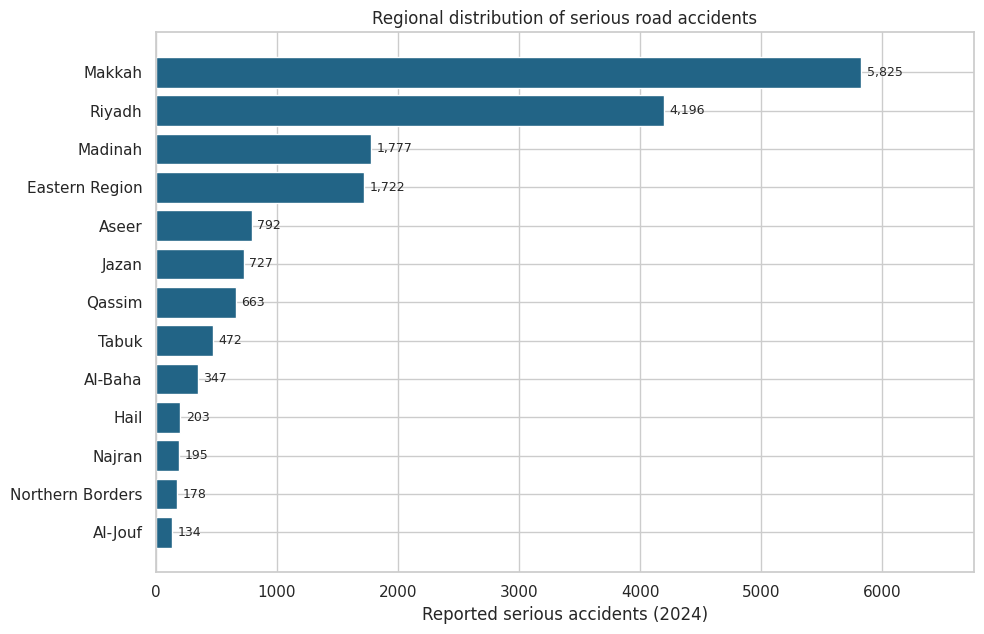

In [6]:
regional["National_Share_Pct"] = 100 * regional.Total_Accidents / regional.Total_Accidents.sum()
regional["Within_Cities_Pct"] = 100 * regional.Within_Cities / regional.Total_Accidents
regional["Outside_Cities_Pct"] = 100 * regional.Outside_Cities / regional.Total_Accidents
ranked = regional.sort_values("Total_Accidents", ascending=False).reset_index(drop=True)
display(ranked.round(2))
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(ranked.Region[::-1], ranked.Total_Accidents[::-1], color="#226486")
ax.set(xlabel="Reported serious accidents (2024)", title="Regional distribution of serious road accidents")
for i, value in enumerate(ranked.Total_Accidents[::-1]):
    ax.text(value + 45, i, f"{value:,}", va="center", fontsize=9)
ax.set_xlim(0, ranked.Total_Accidents.max()*1.16)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_regional_accidents.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Within-city vs outside-city accidents

The percentages describe the **composition of each region's reported serious accidents**; they do not compare accident risk per kilometer or per traveler.

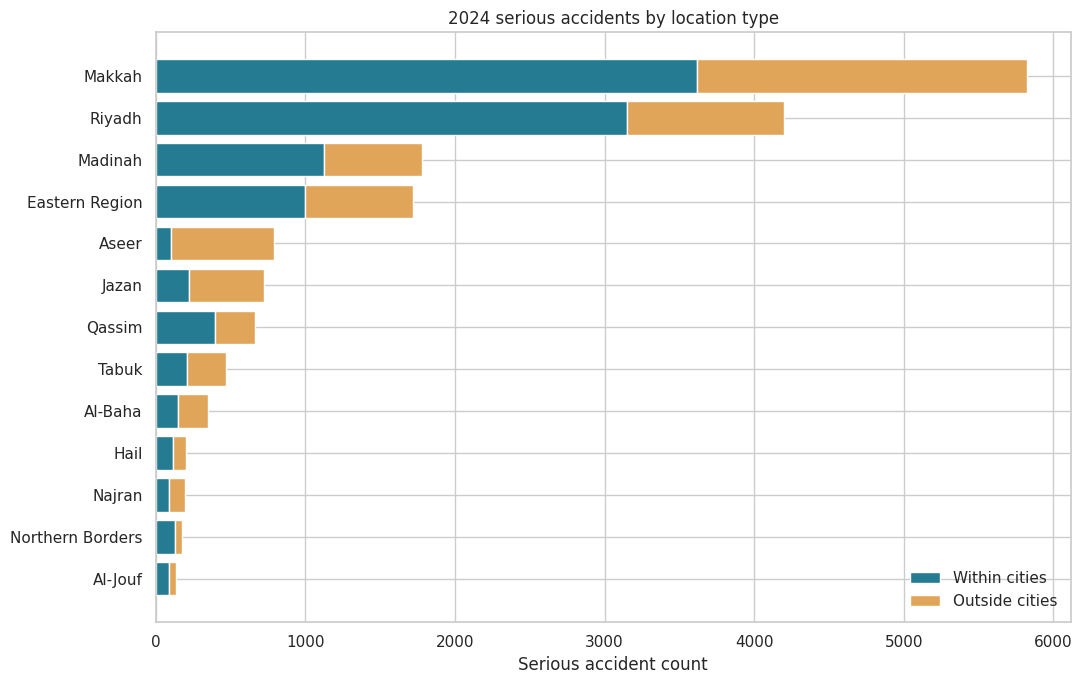

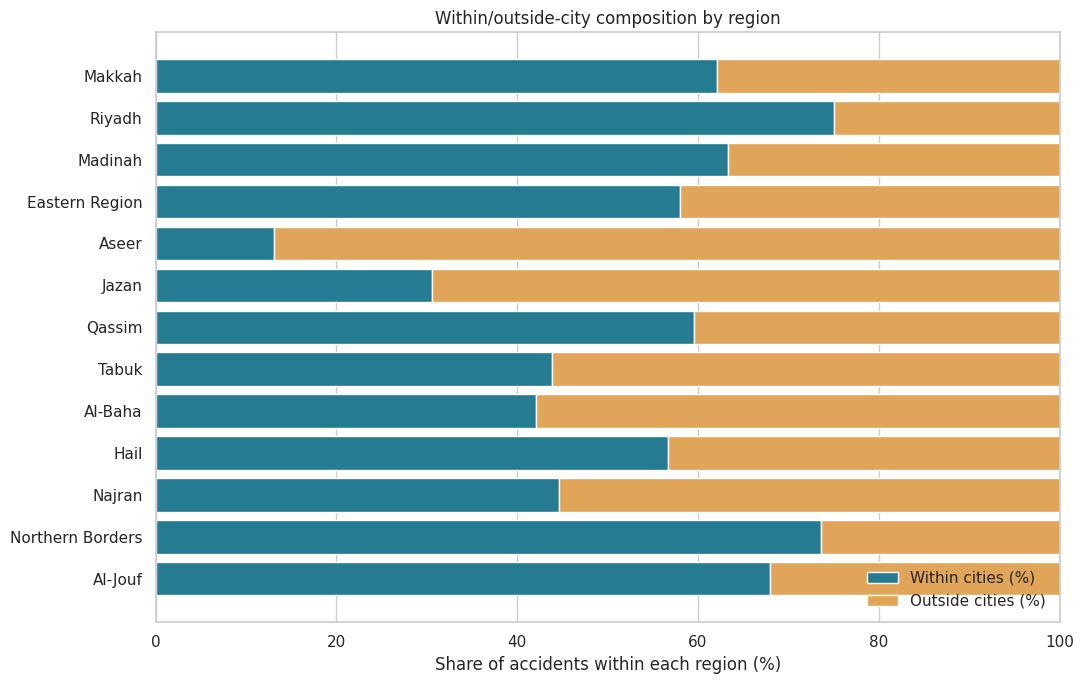

In [7]:
plot_data = regional.sort_values("Total_Accidents", ascending=True)
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(plot_data.Region, plot_data.Within_Cities, label="Within cities", color="#247B92")
ax.barh(plot_data.Region, plot_data.Outside_Cities, left=plot_data.Within_Cities, label="Outside cities", color="#E1A55A")
ax.set(xlabel="Serious accident count", title="2024 serious accidents by location type")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_within_outside_counts.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(plot_data.Region, plot_data.Within_Cities_Pct, label="Within cities (%)", color="#247B92")
ax.barh(plot_data.Region, plot_data.Outside_Cities_Pct, left=plot_data.Within_Cities_Pct, label="Outside cities (%)", color="#E1A55A")
ax.set(xlabel="Share of accidents within each region (%)", xlim=(0, 100), title="Within/outside-city composition by region")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_within_outside_percentages.png", dpi=180, bbox_inches="tight")
plt.show()

## 7. Concentration and reproducible findings

The following findings are generated from the data rather than copied into fixed prose.

In [8]:
total = int(regional.Total_Accidents.sum())
city = int(regional.Within_Cities.sum())
outside = int(regional.Outside_Cities.sum())
top_three = ranked.head(3)
top_three_share = 100 * top_three.Total_Accidents.sum() / total
highest_outside_share = regional.loc[regional.Outside_Cities_Pct.idxmax()]
print(f"2024 serious accidents: {total:,}")
print(f"Within cities: {city:,} ({city/total:.2%})")
print(f"Outside cities: {outside:,} ({outside/total:.2%})")
print(f"Largest region: {ranked.iloc[0].Region}, {ranked.iloc[0].Total_Accidents:,} ({ranked.iloc[0].National_Share_Pct:.2f}%)")
print(f"Top 3 regions: {', '.join(top_three.Region)} | combined share {top_three_share:.2f}%")
print(f"Highest outside-city share: {highest_outside_share.Region} ({highest_outside_share.Outside_Cities_Pct:.2f}%)")
print("Year-over-year changes:")
for name, row in comparison.iterrows():
    print(f"  {name}: {row.Pct_Change:+.2f}%")

2024 serious accidents: 17,231
Within cities: 10,392 (60.31%)
Outside cities: 6,839 (39.69%)
Largest region: Makkah, 5,825 (33.81%)
Top 3 regions: Makkah, Riyadh, Madinah | combined share 68.47%
Highest outside-city share: Aseer (86.87%)
Year-over-year changes:
  Serious_Accidents: +4.22%
  Fatalities: -3.19%
  Injuries: +0.31%


## 8. Verification against the official GASTAT workbook

The embedded regional values were compared with the Arabic *Road Transport Statistics 2024* workbook, sheet `5-5`: **39/39 values matched exactly**. The checked national figures were also reconciled with sheets `5-3` and `5-1`.

The next cell repeats these checks **when the official Excel file is present** in the working directory. The ZIP package includes that file. When the notebook is opened on its own, the analysis still runs using the previously verified embedded snapshot; the audit cell reports that it was skipped in that particular run.


In [9]:
# Reproducible audit against the original Arabic GASTAT workbook (included in full ZIP)
source_file = Path("Road Transport Statistics 2024_AR (1).xlsx")
if source_file.exists():
    workbook = pd.ExcelFile(source_file)
    required_sheets = {"5-1", "5-3", "5-5"}
    assert required_sheets.issubset(workbook.sheet_names), "Missing official source tables"

    region_name_map = {
        "الرياض": "Riyadh", "مكة المكرمة": "Makkah",
        "المدينة المنورة": "Madinah", "القصيم": "Qassim",
        "المنطقة الشرقية": "Eastern Region", "عسير": "Aseer",
        "تبوك": "Tabuk", "حائل": "Hail",
        "الحدود الشمالية": "Northern Borders", "جازان": "Jazan",
        "نجران": "Najran", "الباحة": "Al-Baha", "الجوف": "Al-Jouf"
    }
    official = pd.read_excel(workbook, sheet_name="5-5", header=None).iloc[:, :4].copy()
    official.columns = ["Arabic_Region", "Within_Cities", "Outside_Cities", "Total_Accidents"]
    official["Arabic_Region"] = official["Arabic_Region"].astype(str).str.strip()
    official = official.loc[official["Arabic_Region"].isin(region_name_map)].copy()
    official["Region"] = official["Arabic_Region"].map(region_name_map)
    assert len(official) == 13 and official.Region.is_unique
    for col in ["Within_Cities", "Outside_Cities", "Total_Accidents"]:
        official[col] = pd.to_numeric(official[col], errors="raise").astype(int)
    compare_cols = ["Region", "Within_Cities", "Outside_Cities", "Total_Accidents"]
    pd.testing.assert_frame_equal(
        official[compare_cols].sort_values("Region").reset_index(drop=True),
        regional[compare_cols].sort_values("Region").reset_index(drop=True),
        check_dtype=False,
    )
    casualties = pd.read_excel(workbook, sheet_name="5-1", header=None)
    national = casualties.loc[casualties.iloc[:, 0].astype(str).str.strip().eq("المجموع")]
    assert len(national) == 1
    assert int(national.iloc[0, 1]) == int(annual.loc[annual.Year.eq(2024), "Injuries"].iloc[0])
    assert int(national.iloc[0, 2]) == int(annual.loc[annual.Year.eq(2024), "Fatalities"].iloc[0])
    yearly = pd.read_excel(workbook, sheet_name="5-3", header=None)
    for year in [2023, 2024]:
        match = yearly.loc[yearly.iloc[:, 0].eq(year)]
        assert len(match) == 1
        assert int(match.iloc[0, 1]) == int(annual.loc[annual.Year.eq(year), "Serious_Accidents"].iloc[0])
    print("PASS: Official GASTAT workbook verification")
    print("Regional values: 39/39 exact matches across 13 regions")
    print("National accidents 2023/2024 and 2024 casualties: exact matches")
else:
    print("Official workbook not in working directory; this run skips independent audit.")
    print("The embedded snapshot was previously verified against the supplied official workbook.")

PASS: Official GASTAT workbook verification
Regional values: 39/39 exact matches across 13 regions
National accidents 2023/2024 and 2024 casualties: exact matches


## 9. Outputs and limitations

**Limitations:** The annual comparison covers only two years, so it cannot establish a long-term trend. Regional accident counts are not comparable risk rates without population, traffic-volume, distance-traveled, or other exposure measures. Aggregated data do not support causal conclusions or crash-level predictions. Within-city and outside-city counts describe locations, not the effectiveness of safety measures.

**Outputs:** National and regional CSV tables, a year-over-year comparison CSV, and four charts. The notebook includes saved results so the analysis can be reviewed on GitHub without rerunning it. The official workbook and the separate regional audit CSV are provided in the complete ZIP package.


In [10]:
annual.to_csv(OUTPUT_DIR / "Saudi_Road_Safety_Annual_2023_2024.csv", index=False, encoding="utf-8-sig")
regional.to_csv(OUTPUT_DIR / "Saudi_Road_Safety_Regional_2024.csv", index=False, encoding="utf-8-sig")
comparison.to_csv(OUTPUT_DIR / "Saudi_Road_Safety_Annual_Changes.csv", encoding="utf-8-sig")
print("Saved outputs:")
for file in sorted(OUTPUT_DIR.iterdir()):
    print("-", file.name, f"({file.stat().st_size:,} bytes)")

Saved outputs:
- 01_national_indicators.png (95,050 bytes)
- 02_regional_accidents.png (93,742 bytes)
- 03_within_outside_counts.png (84,892 bytes)
- 04_within_outside_percentages.png (89,940 bytes)
- Saudi_Road_Safety_Annual_2023_2024.csv (220 bytes)
- Saudi_Road_Safety_Annual_Changes.csv (182 bytes)
- Saudi_Road_Safety_Regional_2024.csv (1,092 bytes)
